# 02 · Single-neuron theta/QIF dynamics
## Goal
Establish the dynamics of one canonical Type I neuron before introducing coupling or graphs. This notebook studies equilibria, excitability, repetitive firing, pulse thresholds, and numerical accuracy. The theta neuron and quadratic integrate-and-fire (QIF) neuron are treated as two representations of the same ideal system.

**Scope:** deterministic, dimensionless, single neuron; no experimental calibration, noise, synapses, or network claims. Parameter values are mathematical examples, not fitted neuronal measurements. This extends `01_neuronal_model_catalog.ipynb`.

**Reading order:** derivation → implementation → autonomous dynamics → pulse responses → convergence and cutoff bias → quantitative checks. All figures and computed tables are saved under `results/theta_qif/` relative to the execution directory as well as displayed here. No external data or network access are needed to run the notebook.

## Setup
### Model, coordinates, and units
Write the effective drive as $a(t)=\eta+I(t)$ and choose
$$\dot v=v^2+a(t),\qquad +\infty\mapsto-\infty,$$
$$\dot\theta=1-\cos\theta+[1+\cos\theta]a(t),\qquad v=\tan(\theta/2).$$
The QIF line is compactified by identifying its two infinite ends. Theta evolves continuously on the circle; in code we integrate an **unwrapped** angle. A spike is a forward crossing of $\theta=(2k+1)\pi$. Since $\dot\theta=2$ at those crossings, spikes remain transverse even when input changes. The angle $\theta$ is a state coordinate, **not a uniformly advancing phase** except when $a=1$.

The coordinate identity follows from
$$\dot v=\tfrac12(1+v^2)\dot\theta=v^2+a.$$
It holds away from the tangent poles, while theta gives regular passage through the QIF spike singularity. These standard model conventions are consistent with [Gerstner et al., §5.3](https://neuronaldynamics.epfl.ch/online/Ch5.S3.html). Derivations and numerical experiments below use the explicitly displayed equations.

### Assumptions and reproducibility
- Time and $v,a,\eta,I$ are dimensionless. Frequencies are cycles per model-time unit, **not Hz**. If later $t_{physical}=t_0t$ with $t_0$ in seconds, then $f_{Hz}=f/t_0$; $t_0$ is not chosen here.
- Constant-drive sweeps use exact-period-scaled horizons, avoiding a fixed observation window that misses near-threshold slow spiking.
- Rate is estimated from interspike intervals (ISIs), not spike count divided by an arbitrary finite window.
- Piecewise-constant pulses are integrated in separate segments with a continuous state at each input jump.
- Spike crossings come from solver event interpolation; plotting samples are never used for spike detection.
- No random variables are used. Numerical errors are deterministic discrepancies, not confidence intervals.

Select a Python kernel with NumPy, SciPy, pandas, Matplotlib, IPython, and Jupyter. No installation occurs in this notebook.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

OUTPUT_DIR = Path('results') / 'theta_qif'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {'stable': '#2166AC', 'unstable': '#C56A18',
          'neutral': '#444444', 'sub': '#2166AC', 'super': '#C56A18'}
plt.rcParams.update({'figure.figsize': (9.2, 4.2), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.2,
                     'figure.dpi': 110, 'savefig.dpi': 160})
pd.set_option('display.precision', 7)
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'scipy': scipy.__version__, 'pandas': pd.__version__,
            'matplotlib': matplotlib.__version__}
print(VERSIONS)

def show_and_save(fig, stem):
    fig.savefig(OUTPUT_DIR / f'{stem}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## Steps
### 1. Equilibria, stability, and firing onset
For constant $a<0$, let $b=-a>0$. The two equilibria are
$$v_s=-\sqrt b,\quad v_u=+\sqrt b;\qquad
\lambda_s=-2\sqrt b,\quad\lambda_u=+2\sqrt b.$$
A smooth coordinate change preserves these local eigenvalues. The corresponding theta equilibria are $2\arctan(v_s)$ and $2\arctan(v_u)$ modulo $2\pi$. Rest is asymptotically stable; the unstable point is the excitation boundary. Above it, the state can complete a spike and then return to rest after circle passage. This is excitability, not sustained firing at negative drive.

At $a=0$, $v=0$ is nonhyperbolic and semistable: for initial $v_0<0$,
$$v(t)=\frac{v_0}{1-v_0t}\to0^-,$$
so attraction is algebraic, not exponential. Initial $v_0>0$ reaches a spike singularity in finite time, then approaches zero from below after reinjection; no sustained finite-frequency rotation remains.

For $a>0$ there is no equilibrium and the circle rotates:
$$T_\infty(a)=\int_{-\infty}^{\infty}\frac{dv}{v^2+a}=\frac\pi{\sqrt a},\qquad
f_\infty(a)=\frac{\sqrt a}\pi.$$
Thus $f\to0$ continuously at onset. The circle/reinjection is essential: a saddle-node on the uncompactified real line alone does not create a periodic orbit. This is the SNIC mechanism discussed in [Neuronal Dynamics §4.4](https://neuronaldynamics.epfl.ch/online/Ch4.S4.html).

As $a\to0^-$, the linear relaxation time $1/(2\sqrt{-a})$ diverges. As $a\to0^+$, the period diverges as $a^{-1/2}$. Both provide critical-slowing benchmarks.

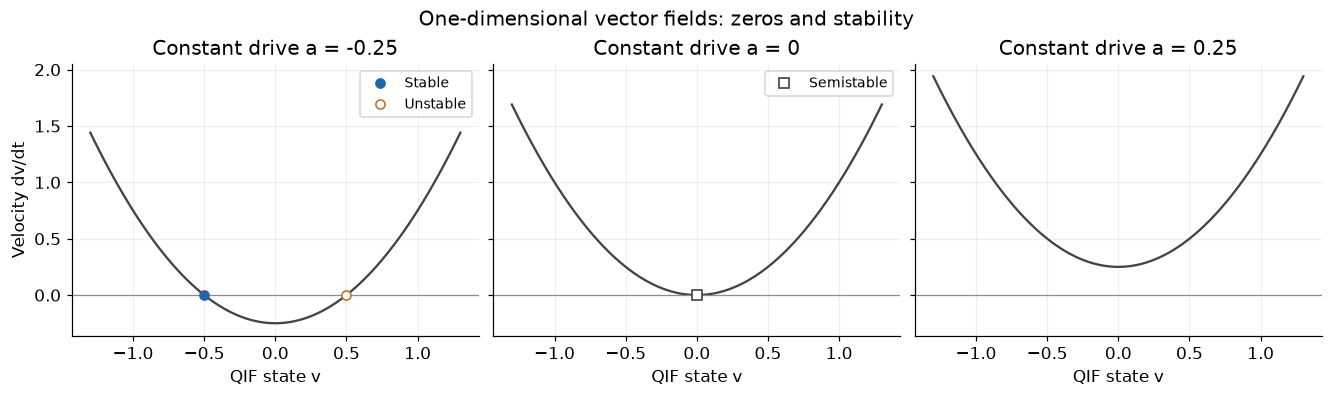

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True, sharey=True,
                         layout='constrained')
v_grid = np.linspace(-1.3, 1.3, 500)
for ax, drive in zip(axes, [-0.25, 0.0, 0.25]):
    ax.plot(v_grid, v_grid**2 + drive, color=COLORS['neutral'])
    ax.axhline(0, color='0.55', linewidth=0.8)
    if drive < 0:
        root = np.sqrt(-drive)
        ax.plot(-root, 0, 'o', color=COLORS['stable'], label='Stable')
        ax.plot(root, 0, 'o', mfc='white', mec=COLORS['unstable'],
                label='Unstable')
        ax.legend(fontsize=9)
    elif drive == 0:
        ax.plot(0, 0, 's', mfc='white', mec='0.2', label='Semistable')
        ax.legend(fontsize=9)
    ax.set(title=f'Constant drive a = {drive:g}', xlabel='QIF state v')
axes[0].set_ylabel('Velocity dv/dt')
fig.suptitle('One-dimensional vector fields: zeros and stability')
show_and_save(fig, '01_vector_fields')

**Interpretation:** below threshold there are attracting and repelling zeros; at threshold they merge; above threshold velocity is positive everywhere. These are one-dimensional vector-field plots, not voltage waveforms or biophysical phase planes.

### 2. Event-aware theta integrator
The event function $\cos(\theta/2)$ vanishes at every odd multiple of $\pi$. Its sign-crossing direction alternates with the winding number, so we accept both directions of the event function; the physical angular velocity at every root is positive. For a segment with constant drive,
$$|\dot\theta|\leq 2\max(1,|a|).$$
We cap each solver step to allow at most $\pi$ total angular travel, less than the $2\pi$ separation of successive spikes. This prevents an adaptive step from silently spanning multiple events. The starting state is $\theta_0=0$ unless specified; this is not itself a spike.

In [5]:
def theta_rhs(theta, drive):
    return 1.0 - np.cos(theta) + drive * (1.0 + np.cos(theta))

def spike_event(t, state):
    return np.cos(state[0] / 2.0)

spike_event.terminal = False
spike_event.direction = 0

def theta_segment(drive, t_span, theta0=0.0, *, rtol=1e-9, atol=1e-11,
                  max_step=0.5, method='DOP853'):
    """Constant-drive segment, unwrapped angle, interpolated spike events."""
    if not np.isfinite(drive) or not t_span[1] > t_span[0]:
        raise ValueError('Require finite drive and increasing time interval.')
    safe_step = np.pi / (2.0 * max(1.0, abs(drive)))
    solution = solve_ivp(
        lambda t, state: [theta_rhs(state[0], drive)], t_span, [theta0],
        method=method, rtol=rtol, atol=atol,
        max_step=min(max_step, safe_step), dense_output=True,
        events=spike_event)
    if not solution.success:
        raise RuntimeError(solution.message)
    return solution

def exact_period(drive):
    if drive <= 0:
        raise ValueError('A finite repetitive-firing period requires a > 0.')
    return np.pi / np.sqrt(drive)

def spike_statistics(solution):
    spikes = solution.t_events[0]
    if len(spikes) < 3:
        raise ValueError('At least 3 spike events required for this benchmark.')
    intervals = np.diff(spikes)
    return {'period': float(intervals.mean()),
            'frequency': float(1.0 / intervals.mean()),
            'isi_cv': float(intervals.std(ddof=0) / intervals.mean()),
            'n_spikes': int(len(spikes))}

def wrapped_for_plot(theta):
    wrapped = (np.asarray(theta) + np.pi) % (2*np.pi) - np.pi
    wrapped = wrapped.copy()
    jumps = np.flatnonzero(np.abs(np.diff(wrapped)) > np.pi) + 1
    wrapped[jumps] = np.nan  # do not draw a vertical line through a wrap
    return wrapped

### 3. Coordinate consistency on a nonsingular trajectory
Here $a=0.25$, $v(0)=-1$, and $0\leq t\leq4$ remain before the first QIF pole. We independently integrate both equations and compare with the exact tangent solution. Near a pole, voltage-coordinate error is ill-conditioned; those points are deliberately outside this check.

In [7]:
coordinate_drive, coordinate_v0 = 0.25, -1.0
coordinate_t = np.linspace(0, 4, 801)
coordinate_theta = theta_segment(coordinate_drive, (0, 4),
                                 theta0=2*np.arctan(coordinate_v0),
                                 rtol=1e-11, atol=1e-13)
coordinate_qif = solve_ivp(
    lambda t, state: [state[0]**2 + coordinate_drive], (0, 4),
    [coordinate_v0], method='DOP853', rtol=1e-11, atol=1e-13,
    dense_output=True, max_step=0.25)
assert coordinate_qif.success
qif_direct = coordinate_qif.sol(coordinate_t)[0]
qif_from_theta = np.tan(coordinate_theta.sol(coordinate_t)[0]/2)
qif_exact = np.sqrt(coordinate_drive)*np.tan(
    np.sqrt(coordinate_drive)*coordinate_t
    + np.arctan(coordinate_v0/np.sqrt(coordinate_drive)))
coordinate_error = float(np.max(np.abs(qif_direct - qif_from_theta)))
coordinate_exact_error = float(np.max(np.abs(qif_direct - qif_exact)))
print(f'Maximum |direct QIF - transformed theta|: {coordinate_error:.3e}')
print(f'Maximum |direct QIF - exact solution|: {coordinate_exact_error:.3e}')
assert coordinate_error < 1e-8
assert coordinate_exact_error < 1e-8

Maximum |direct QIF - transformed theta|: 3.358e-11
Maximum |direct QIF - exact solution|: 7.450e-12


### 4. Constant-drive trajectories
Use three inputs and explicit initial conditions: $a=-0.25,v_0=0$ (relaxation to rest), $a=0,v_0=-0.5$ (algebraic approach), and $a=0.25,v_0=0$ (repetitive firing). Wrapped theta is plotted only for readability; integration remains unwrapped. At negative drive the unstable point is $\theta_u=2\arctan(0.5)$.

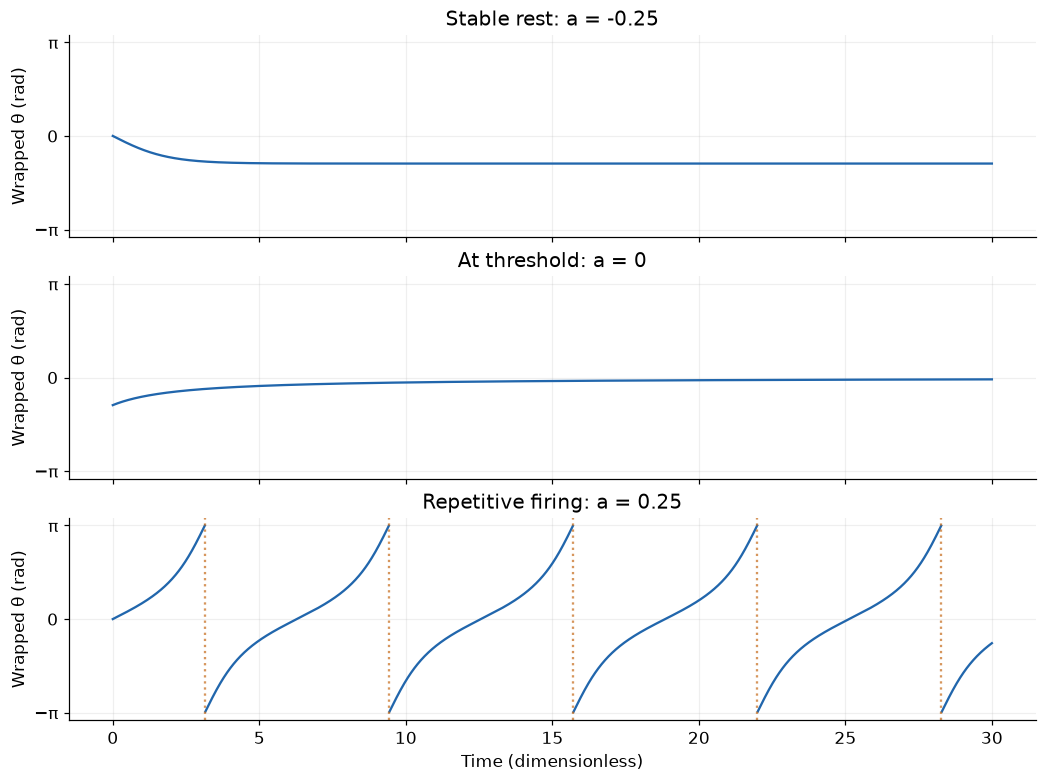

At a=0, maximum error versus algebraic solution: 1.306e-10


In [9]:
regimes = [(-0.25, 0.0, 'Stable rest'),
           (0.0, 2*np.arctan(-0.5), 'At threshold'),
           (0.25, 0.0, 'Repetitive firing')]
regime_solutions = []
fig, axes = plt.subplots(3, 1, figsize=(9.4, 7), sharex=True,
                         layout='constrained')
regime_time = np.linspace(0, 30, 3001)
for ax, (drive, theta0, label) in zip(axes, regimes):
    sol = theta_segment(drive, (0, 30), theta0)
    regime_solutions.append(sol)
    ax.plot(regime_time, wrapped_for_plot(sol.sol(regime_time)[0]),
            color=COLORS['stable'])
    for spike in sol.t_events[0]:
        ax.axvline(spike, color=COLORS['unstable'], linestyle=':', alpha=0.7)
    ax.set(title=f'{label}: a = {drive:g}', ylabel='Wrapped θ (rad)',
           ylim=(-3.4, 3.4))
    ax.set_yticks([-np.pi, 0, np.pi], ['−π', '0', 'π'])
axes[-1].set_xlabel('Time (dimensionless)')
show_and_save(fig, '02_constant_drive_trajectories')
assert len(regime_solutions[0].t_events[0]) == 0
assert len(regime_solutions[1].t_events[0]) == 0
critical_v_numerical = np.tan(regime_solutions[1].sol(regime_time)[0] / 2)
critical_v_exact = -0.5 / (1 + 0.5*regime_time)
critical_error = float(np.max(np.abs(critical_v_numerical-critical_v_exact)))
assert critical_error < 1e-8
print(f'At a=0, maximum error versus algebraic solution: {critical_error:.3e}')

**Interpretation:** rest and threshold trajectories do not rotate for these initial conditions. Positive drive yields periodic spikes. A wrapped angle jumps by construction at a spike; the underlying theta trajectory is continuous. There is no independently modeled action-potential amplitude or refractory variable.

### 5. Bifurcation diagram and firing-rate curve
The numerical sweep uses 17 logarithmically spaced positive drives from $10^{-3}$ to $1$. Each run lasts $3.2T_\infty(a)$, starting at $\theta=0$, giving three spikes and two ISIs. This is a steady autonomous oscillator with identical successive cycles, so no arbitrary transient-discard period is needed. It is a deliberately period-aware benchmark; a practical unknown-model experiment would have to establish its own adequate horizon.

,a,period_exact,period_numeric,frequency_numeric,relative_period_error
0,0.0010000,99.3458827,99.3458827,0.0100658,2.5561775e-12
4,0.0056234,41.8938113,41.8938113,0.0238699,1.6113999e-11
8,0.0316228,17.6664738,17.6664738,0.0566044,7.7600926e-11
12,0.1778279,7.4498902,7.4498902,0.1342302,2.5398839e-10
16,1.0000000,3.1415927,3.1415927,0.3183099,2.2204460e-16


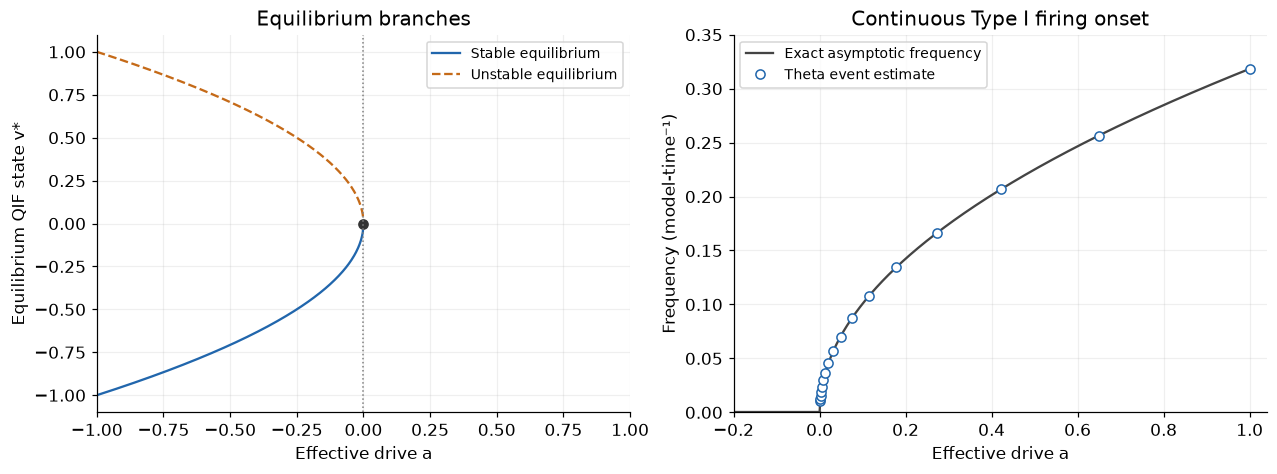

Fitted log(f) versus log(a) slope: 0.5000000000; exact: 0.5


In [11]:
drive_values = np.geomspace(1e-3, 1.0, 17)
rate_rows = []
for drive in drive_values:
    period_ref = exact_period(drive)
    sol = theta_segment(drive, (0, 3.2*period_ref))
    stats = spike_statistics(sol)
    rate_rows.append({'a': drive, 'period_exact': period_ref,
                     'period_numeric': stats['period'],
                     'frequency_exact': 1/period_ref,
                     'frequency_numeric': stats['frequency'],
                     'relative_period_error': abs(stats['period']/period_ref-1),
                     'isi_cv': stats['isi_cv'], 'n_spikes': stats['n_spikes']})
rate_table = pd.DataFrame(rate_rows)
rate_table.to_csv(OUTPUT_DIR / 'firing_rate_sweep.csv', index=False)
display(rate_table.iloc[[0, 4, 8, 12, 16]][
    ['a', 'period_exact', 'period_numeric', 'frequency_numeric',
     'relative_period_error']])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
a_negative = np.linspace(-1, 0, 400)
axes[0].plot(a_negative, -np.sqrt(-a_negative), color=COLORS['stable'],
             label='Stable equilibrium')
axes[0].plot(a_negative, np.sqrt(-a_negative), '--', color=COLORS['unstable'],
             label='Unstable equilibrium')
axes[0].plot(0, 0, 'o', color='0.2')
axes[0].axvline(0, color='0.5', linestyle=':', linewidth=1)
axes[0].set(xlabel='Effective drive a', ylabel='Equilibrium QIF state v*',
            title='Equilibrium branches', xlim=(-1, 1))
axes[0].legend(fontsize=9)
a_positive = np.linspace(0, 1, 500)
axes[1].plot([-0.2, 0], [0, 0], color=COLORS['neutral'])
axes[1].plot(a_positive, np.sqrt(a_positive)/np.pi,
             color=COLORS['neutral'], label='Exact asymptotic frequency')
axes[1].plot(rate_table.a, rate_table.frequency_numeric, 'o',
             mfc='white', mec=COLORS['stable'], label='Theta event estimate')
axes[1].set(xlabel='Effective drive a', ylabel='Frequency (model-time⁻¹)',
            title='Continuous Type I firing onset', xlim=(-0.2, 1.04), ylim=(0, 0.35))
axes[1].legend(fontsize=9)
show_and_save(fig, '03_bifurcation_and_rate')
rate_slope = float(np.polyfit(np.log(rate_table.a),
                              np.log(rate_table.frequency_numeric), 1)[0])
print(f'Fitted log(f) versus log(a) slope: {rate_slope:.10f}; exact: 0.5')

**Interpretation:** the stable and unstable branches meet at $a=0$; sustained frequency is zero for $a\leq0$ and grows as $\sqrt a$ above onset. This rate curve describes the ideal mathematical system in model units, not a fit to measured neurons. A possible isolated spike from a specially chosen initial condition below threshold does not change the asymptotic frequency.

### 6. Square-pulse excitability and strength–duration threshold
Fix baseline $a=-b$ with $b=0.25$, start at the exact rest $v_s=-\sqrt b=-0.5$, and apply an additive square pulse of amplitude $A=0.75$. During the pulse $c=A-b=0.5>0$. A pulse triggers a post-pulse excursion if it carries the state beyond $v_u=+\sqrt b$. The critical duration, before any pole is crossed, follows by quadrature:
$$D_{crit}(A;b)=\int_{-\sqrt b}^{+\sqrt b}\frac{dv}{v^2+(A-b)}
=\frac{2}{\sqrt{A-b}}\arctan\sqrt{\frac b{A-b}},\qquad A>b.$$
Equality lands exactly on the unstable equilibrium and is not a robust spike. For $A\leq b$, no finite-duration constant pulse can move exact rest past $v_u$ in this noiseless setting.

We compare $0.8D_{crit}$ and $1.2D_{crit}$, with onset $t=5$. The runs stop at $t=30$. The pulse durations here are shorter than the time to the first spike during the pulse, so threshold classification by endpoint is valid. For longer pulses one must count rotations, not compare a principal angle alone.

Analytic critical duration: 1.740839503


,case,duration,duration_over_critical,v_at_pulse_end,n_spikes,first_spike_time
0,Below threshold,1.3926716,0.8,0.2736815,0,NaN
1,Above threshold,2.0890074,1.2,0.8241262,1,8.4963825


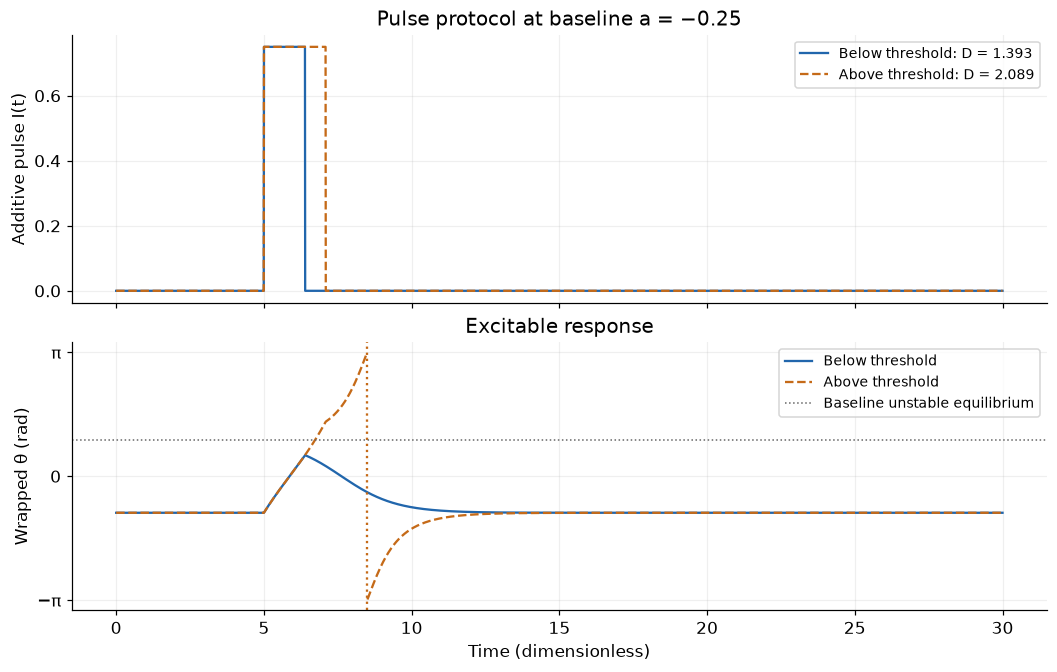

In [13]:
def pulse_critical_duration(amplitude, baseline_b):
    if baseline_b <= 0 or amplitude <= baseline_b:
        raise ValueError('Require b > 0 and A > b for a finite threshold.')
    c = amplitude - baseline_b
    return 2*np.arctan(np.sqrt(baseline_b/c))/np.sqrt(c)

def piecewise_theta(segments, theta0, **solver_options):
    """Segments are (start, stop, effective_drive); state is continuous."""
    solutions, spike_arrays = [], []
    state = float(theta0)
    previous_stop = None
    for start, stop, drive in segments:
        if previous_stop is not None and not np.isclose(start, previous_stop):
            raise ValueError('Segments must be contiguous.')
        sol = theta_segment(drive, (start, stop), state, **solver_options)
        solutions.append(sol)
        spike_arrays.append(sol.t_events[0])
        state = float(sol.y[0, -1])
        previous_stop = stop
    spikes = np.concatenate(spike_arrays)
    # A root exactly at a segment boundary may be returned twice.
    if len(spikes):
        spikes = spikes[np.r_[True, np.diff(spikes) > 1e-8]]
    return solutions, spikes

def sample_piecewise(solutions, times):
    theta = np.full_like(times, np.nan, dtype=float)
    for sol in solutions:
        select = (times >= sol.t[0]) & (times <= sol.t[-1])
        theta[select] = sol.sol(times[select])[0]
    if not np.isfinite(theta).all():
        raise ValueError('Sampling times outside protocol interval.')
    return theta

baseline_b, pulse_amplitude, pulse_onset = 0.25, 0.75, 5.0
pulse_end_time = 30.0
rest_theta = 2*np.arctan(-np.sqrt(baseline_b))
threshold_theta = 2*np.arctan(np.sqrt(baseline_b))
critical_duration = pulse_critical_duration(pulse_amplitude, baseline_b)
pulse_runs, pulse_rows = {}, []
for factor, label in [(0.8, 'Below threshold'), (1.2, 'Above threshold')]:
    duration = factor*critical_duration
    off = pulse_onset + duration
    protocol = [(0, pulse_onset, -baseline_b),
                (pulse_onset, off, pulse_amplitude-baseline_b),
                (off, pulse_end_time, -baseline_b)]
    solutions, spikes = piecewise_theta(protocol, rest_theta)
    endpoint_v = float(np.tan(solutions[1].y[0, -1]/2))
    pulse_runs[label] = (duration, solutions, spikes)
    pulse_rows.append({'case': label, 'duration': duration,
                       'duration_over_critical': factor,
                       'v_at_pulse_end': endpoint_v, 'n_spikes': len(spikes),
                       'first_spike_time': float(spikes[0]) if len(spikes) else np.nan})
pulse_table = pd.DataFrame(pulse_rows)
pulse_table.to_csv(OUTPUT_DIR / 'pulse_responses.csv', index=False)
print(f'Analytic critical duration: {critical_duration:.9f}')
display(pulse_table)

fig, axes = plt.subplots(2, 1, figsize=(9.5, 6), sharex=True,
                         layout='constrained')
pulse_times = np.linspace(0, pulse_end_time, 4001)
for label, style, color in [('Below threshold', '-', COLORS['sub']),
                            ('Above threshold', '--', COLORS['super'])]:
    duration, solutions, spikes = pulse_runs[label]
    input_trace = np.where((pulse_times >= pulse_onset) &
                           (pulse_times < pulse_onset+duration), pulse_amplitude, 0)
    axes[0].plot(pulse_times, input_trace, style, color=color,
                 label=f'{label}: D = {duration:.3f}')
    theta_trace = sample_piecewise(solutions, pulse_times)
    axes[1].plot(pulse_times, wrapped_for_plot(theta_trace), style,
                 color=color, label=label)
    for spike in spikes:
        axes[1].axvline(spike, linestyle=':', color=color)
axes[0].set(ylabel='Additive pulse I(t)', title='Pulse protocol at baseline a = −0.25')
axes[1].axhline(threshold_theta, color='0.4', linestyle=':',
                linewidth=1, label='Baseline unstable equilibrium')
axes[1].set(xlabel='Time (dimensionless)', ylabel='Wrapped θ (rad)',
            title='Excitable response', ylim=(-3.4, 3.4))
axes[1].set_yticks([-np.pi, 0, np.pi], ['−π', '0', 'π'])
for ax in axes:
    ax.legend(fontsize=9, loc='upper right')
show_and_save(fig, '04_pulse_responses')

**Interpretation:** crossing the unstable state is the relevant excitation criterion. The subthreshold pulse returns to rest without a spike; the suprathreshold pulse produces one excursion and then returns to rest. This example has no additional adaptive or refractory state. It should not be used to infer a measured neuron's refractory period.

We now independently locate the critical pulse duration by root-finding the **numerically integrated** pulse-end angle relative to the baseline unstable angle, and compare with the closed-form threshold. The bracket stays before the first pole. Strength–duration curves below are analytic; only the marked amplitude is checked by this numerical root calculation.

Numerical critical duration: 1.740839503
Relative discrepancy: 4.637e-13


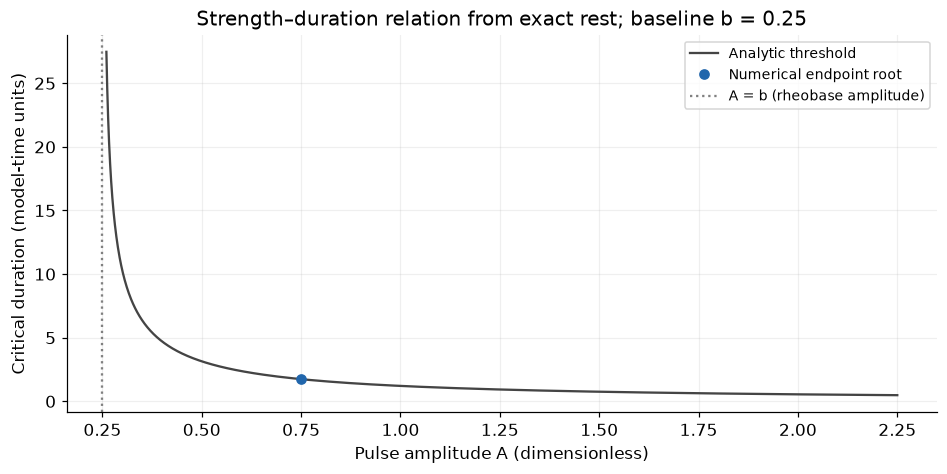

In [15]:
def endpoint_margin(duration):
    sol = theta_segment(pulse_amplitude-baseline_b, (0, duration),
                        rest_theta, rtol=1e-11, atol=1e-13)
    return float(sol.y[0, -1] - threshold_theta)

critical_duration_numeric = brentq(endpoint_margin,
                                  0.7*critical_duration, 1.3*critical_duration,
                                  xtol=1e-11, rtol=1e-12)
critical_relative_error = abs(critical_duration_numeric/critical_duration - 1)
print(f'Numerical critical duration: {critical_duration_numeric:.9f}')
print(f'Relative discrepancy: {critical_relative_error:.3e}')
amplitudes = baseline_b + np.geomspace(0.01, 2, 250)
durations = np.array([pulse_critical_duration(A, baseline_b) for A in amplitudes])
fig, ax = plt.subplots(figsize=(8.5, 4.2), layout='constrained')
ax.plot(amplitudes, durations, color=COLORS['neutral'], label='Analytic threshold')
ax.plot(pulse_amplitude, critical_duration_numeric, 'o',
        color=COLORS['stable'], label='Numerical endpoint root')
ax.axvline(baseline_b, color='0.5', linestyle=':', label='A = b (rheobase amplitude)')
ax.set(xlabel='Pulse amplitude A (dimensionless)',
       ylabel='Critical duration (model-time units)',
       title='Strength–duration relation from exact rest; baseline b = 0.25')
ax.legend(fontsize=9)
show_and_save(fig, '05_strength_duration')

### 7. Solver convergence against the exact period
At $a=0.25$, exact spike times from $\theta(0)=0$ are $(k+1/2)T_\infty$, $k=0,1,\ldots$. Compare both mean ISI error and maximum absolute spike-time error. Tightening tolerances tests integration/event-interpolation error, not statistical uncertainty.

Two RK45 sweeps separate controls: (i) decreasing `rtol` with `atol = rtol/100` and `max_step = 1`; (ii) halving `max_step` at loose fixed tolerances. A tighter DOP853 run supplies an additional method comparison. Monotonic error reduction is not assumed at every setting because adaptive meshes, interpolation, and roundoff can change the pattern.

,sweep,method,rtol,max_step,nfev,relative_period_error,max_spike_time_error
0,tolerance,RK45,1.0000000e-03,1.000,146,2.8451042e-04,2.6785457e-03
1,tolerance,RK45,1.0000000e-05,1.000,224,1.2893204e-04,1.6027476e-03
2,tolerance,RK45,1.0000000e-07,1.000,464,8.4488343e-08,1.6193291e-06
3,tolerance,RK45,1.0000000e-09,1.000,926,8.2939211e-10,1.6029794e-08
4,tolerance,RK45,1.0000000e-11,1.000,2042,2.5913272e-11,3.8160763e-10
5,step,RK45,1.0000000e-02,1.000,146,2.8451042e-04,2.6785457e-03
6,step,RK45,1.0000000e-02,0.500,266,1.7400432e-06,3.6131734e-05
7,step,RK45,1.0000000e-02,0.250,506,4.0749689e-08,1.3000146e-06
8,step,RK45,1.0000000e-02,0.125,986,5.0631395e-09,3.8678374e-08
9,method,DOP853,1.0000000e-11,0.500,1562,1.2978507e-13,2.6680880e-12


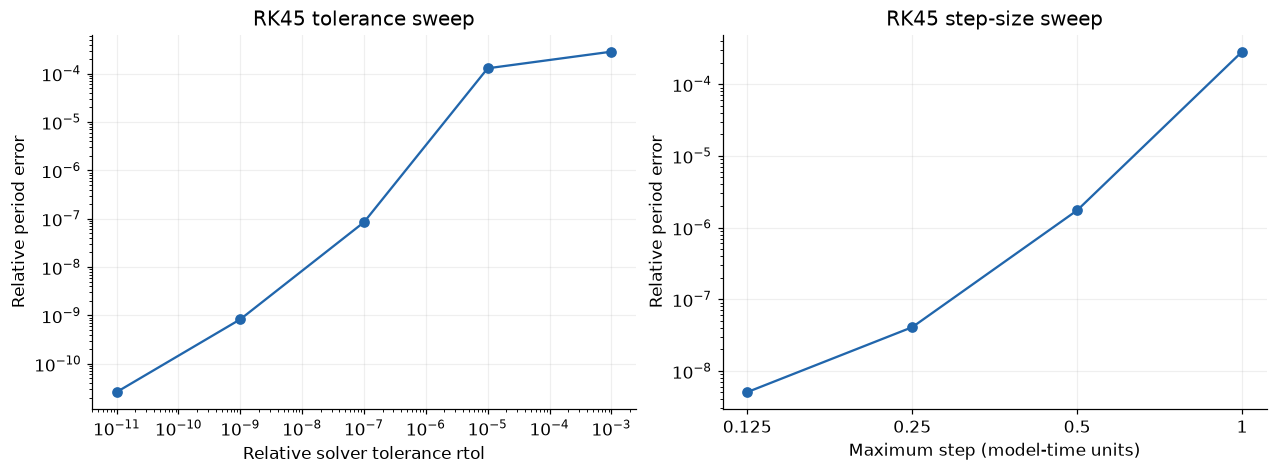

In [17]:
benchmark_drive = 0.25
benchmark_period = exact_period(benchmark_drive)

def benchmark_row(method, rtol, max_step, sweep):
    sol = theta_segment(benchmark_drive, (0, 3.2*benchmark_period),
                        method=method, rtol=rtol, atol=rtol/100,
                        max_step=max_step)
    stats = spike_statistics(sol)
    exact_spikes = (np.arange(len(sol.t_events[0])) + 0.5)*benchmark_period
    return {'sweep': sweep, 'method': method, 'rtol': rtol,
            'max_step': max_step, 'nfev': sol.nfev,
            'relative_period_error': abs(stats['period']/benchmark_period-1),
            'max_spike_time_error': float(np.max(np.abs(sol.t_events[0]-exact_spikes)))}

convergence_rows = [benchmark_row('RK45', tol, 1.0, 'tolerance')
                    for tol in [1e-3, 1e-5, 1e-7, 1e-9, 1e-11]]
convergence_rows += [benchmark_row('RK45', 1e-2, step, 'step')
                     for step in [1.0, 0.5, 0.25, 0.125]]
convergence_rows += [benchmark_row('DOP853', 1e-11, 0.5, 'method')]
convergence_table = pd.DataFrame(convergence_rows)
convergence_table.to_csv(OUTPUT_DIR / 'solver_convergence.csv', index=False)
display(convergence_table[['sweep', 'method', 'rtol', 'max_step',
                           'nfev', 'relative_period_error', 'max_spike_time_error']])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
for ax, sweep, xcol, xlabel in [
    (axes[0], 'tolerance', 'rtol', 'Relative solver tolerance rtol'),
    (axes[1], 'step', 'max_step', 'Maximum step (model-time units)')]:
    part = convergence_table[convergence_table.sweep == sweep]
    ax.loglog(part[xcol], part.relative_period_error, 'o-', color=COLORS['stable'])
    ax.set(xlabel=xlabel, ylabel='Relative period error',
           title='RK45 tolerance sweep' if sweep == 'tolerance' else 'RK45 step-size sweep')
axes[1].set_xticks([0.125, 0.25, 0.5, 1.0], ['0.125', '0.25', '0.5', '1'])
axes[1].set_xticks([], minor=True)
show_and_save(fig, '06_solver_convergence')

### 8. Finite QIF cutoff/reset bias is a different error
For $a>0$, a QIF solver with finite reset $v_r$ and event cutoff $v_{cut}$ measures
$$T_{finite}=\frac1{\sqrt a}\left[\arctan\frac{v_{cut}}{\sqrt a}
-\arctan\frac{v_r}{\sqrt a}\right].$$
For symmetric $v_r=-L$, $v_{cut}=L$,
$$T_L=\frac2{\sqrt a}\arctan\frac L{\sqrt a}<T_\infty.$$
It omits the fast trajectory tails. Consequently finite cutoffs shorten the period and overestimate firing rate even for an exact integrator. For fixed $a$ and large $L$, $T_\infty-T_L\sim2/L$. Repetition of this reset-to-cutoff segment gives the finite-reset oscillator's period; no refractory hold is added.

We directly integrate one reset-to-cutoff QIF segment for each $L$ at $a=0.25$. Compare numerical integration error **against $T_L$**, and modeling/cutoff bias **against $T_\infty$** separately.

,L,period_finite_exact,period_numeric,relative_integration_error,relative_period_bias,relative_frequency_bias
0,2.0,5.3032707,5.3032707,6.7945649e-14,0.1559583,0.1847755
1,5.0,5.8845107,5.8845107,4.2092996e-12,0.0634510,0.0677498
2,10.0,6.0833517,6.0833517,1.4017676e-12,0.0318045,0.0328493
3,20.0,6.1832061,6.1832061,1.1788348e-12,0.0159122,0.0161695
4,50.0,6.2431866,6.2431866,1.6759927e-12,0.0063660,0.0064068
5,100.0,6.2631855,6.2631855,1.6202595e-12,0.0031831,0.0031932


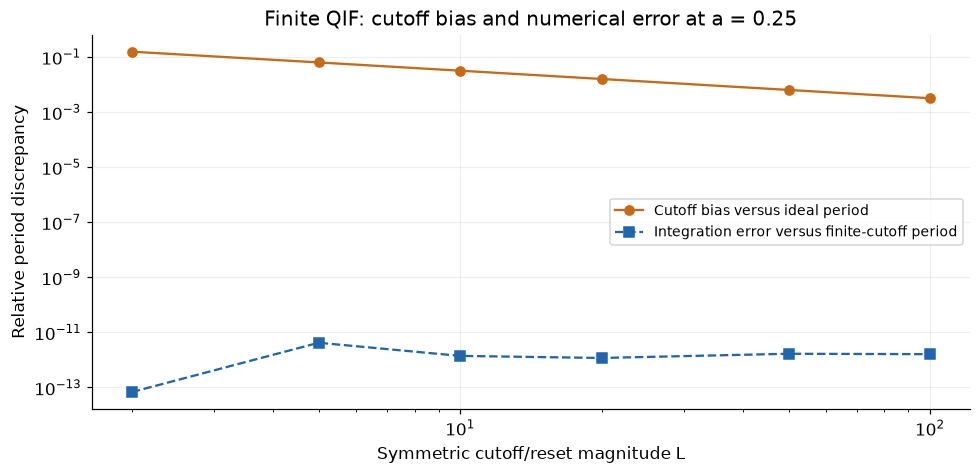

In [19]:
def finite_qif_period(drive, cutoff):
    if drive <= 0 or cutoff <= 0:
        raise ValueError('Require positive drive and symmetric cutoff L > 0.')
    def cutoff_event(t, state):
        return state[0] - cutoff
    cutoff_event.terminal = True
    cutoff_event.direction = 1
    sol = solve_ivp(lambda t, state: [state[0]**2 + drive],
                    (0, exact_period(drive)), [-cutoff], events=cutoff_event,
                    method='DOP853', rtol=1e-10, atol=1e-12, max_step=0.125)
    if not sol.success or len(sol.t_events[0]) != 1:
        raise RuntimeError('Finite QIF cutoff event not found.')
    return float(sol.t_events[0][0])

cutoff_rows = []
for cutoff in [2., 5., 10., 20., 50., 100.]:
    period_finite = 2/np.sqrt(benchmark_drive)*np.arctan(cutoff/np.sqrt(benchmark_drive))
    period_numerical = finite_qif_period(benchmark_drive, cutoff)
    cutoff_rows.append({'L': cutoff, 'period_finite_exact': period_finite,
                       'period_numeric': period_numerical,
                       'relative_integration_error': abs(period_numerical/period_finite-1),
                       'relative_period_bias': 1-period_finite/benchmark_period,
                       'relative_frequency_bias': benchmark_period/period_finite-1})
cutoff_table = pd.DataFrame(cutoff_rows)
cutoff_table.to_csv(OUTPUT_DIR / 'finite_cutoff_bias.csv', index=False)
display(cutoff_table[['L', 'period_finite_exact', 'period_numeric',
                      'relative_integration_error', 'relative_period_bias',
                      'relative_frequency_bias']])
fig, ax = plt.subplots(figsize=(8.8, 4.2), layout='constrained')
ax.loglog(cutoff_table.L, cutoff_table.relative_period_bias, 'o-',
          color=COLORS['unstable'], label='Cutoff bias versus ideal period')
ax.loglog(cutoff_table.L, cutoff_table.relative_integration_error, 's--',
          color=COLORS['stable'], label='Integration error versus finite-cutoff period')
ax.set(xlabel='Symmetric cutoff/reset magnitude L', ylabel='Relative period discrepancy',
       title='Finite QIF: cutoff bias and numerical error at a = 0.25')
ax.legend(fontsize=9, loc='center right')
show_and_save(fig, '07_finite_cutoff_bias')

## Checks
### Numerical acceptance criteria and evidence
These thresholds are declared numerical accuracy goals for these experiments, not universal guarantees. They compare against analytic solutions, independent quadrature, or known qualitative outcomes. Future parameter changes must rerun the checks. No assertion requires every intermediate convergence row to improve monotonically.

In [21]:
quadrature_period, quadrature_estimated_error = quad(
    lambda value: 1/(value*value + benchmark_drive), -np.inf, np.inf,
    epsabs=1e-11, epsrel=1e-11)
tight_rk = convergence_table[(convergence_table.sweep == 'tolerance') &
                              (convergence_table.rtol == 1e-11)].iloc[0]
loose_rk = convergence_table[(convergence_table.sweep == 'tolerance') &
                              (convergence_table.rtol == 1e-3)].iloc[0]
reference_method = convergence_table[convergence_table.sweep == 'method'].iloc[0]
check_rows = [
    ('Coordinate agreement, nonsingular interval', coordinate_error, 1e-8),
    ('Direct QIF versus exact trajectory', coordinate_exact_error, 1e-8),
    ('Threshold algebraic trajectory', critical_error, 1e-8),
    ('Max rate-sweep relative period error', rate_table.relative_period_error.max(), 1e-7),
    ('Rate scaling exponent |slope - 0.5|', abs(rate_slope-0.5), 1e-6),
    ('Pulse-duration relative threshold error', critical_relative_error, 1e-8),
    ('Tight RK45 relative period error', tight_rk.relative_period_error, 1e-8),
    ('Tight DOP853 relative period error', reference_method.relative_period_error, 1e-9),
    ('Max finite-QIF relative integration error', cutoff_table.relative_integration_error.max(), 1e-8),
    ('Independent quadrature relative period error', abs(quadrature_period/benchmark_period-1), 1e-10)]
check_table = pd.DataFrame(check_rows, columns=['check', 'observed_error', 'limit'])
check_table['passed'] = check_table.observed_error < check_table.limit
assert check_table.passed.all(), check_table.loc[~check_table.passed]
assert tight_rk.relative_period_error < loose_rk.relative_period_error
assert pulse_table.n_spikes.tolist() == [0, 1]
assert pulse_table.v_at_pulse_end.iloc[0] < np.sqrt(baseline_b)
assert pulse_table.v_at_pulse_end.iloc[1] > np.sqrt(baseline_b)
assert pulse_table.first_spike_time.iloc[1] > pulse_onset + pulse_table.duration.iloc[1]
assert np.all(rate_table.n_spikes == 3)
assert np.all(np.diff(cutoff_table.relative_period_bias) < 0)
assert np.all(cutoff_table.relative_frequency_bias > 0)
check_table.to_csv(OUTPUT_DIR / 'validation_checks.csv', index=False)
display(check_table)
print('All analytic/numerical checks and pulse/event-count assertions passed.')

,check,observed_error,limit,passed
0,"Coordinate agreement, nonsingular interval",3.3579362e-11,1.0000000e-08,True
1,Direct QIF versus exact trajectory,7.4503737e-12,1.0000000e-08,True
2,Threshold algebraic trajectory,1.3062335e-10,1.0000000e-08,True
3,Max rate-sweep relative period error,3.0242453e-10,1.0000000e-07,True
4,Rate scaling exponent |slope - 0.5|,2.3587909e-11,1.0000000e-06,True
5,Pulse-duration relative threshold error,4.6374016e-13,1.0000000e-08,True
6,Tight RK45 relative period error,2.5913272e-11,1.0000000e-08,True
7,Tight DOP853 relative period error,1.2978507e-13,1.0000000e-09,True
8,Max finite-QIF relative integration error,4.2092996e-12,1.0000000e-08,True
9,Independent quadrature relative period error,0.0000000e+00,1.0000000e-10,True


All analytic/numerical checks and pulse/event-count assertions passed.


## Takeaways
The quantitative summary below is generated from executed results, so values update with the experiment. Numerical accuracy here establishes agreement with this mathematical model; it does not establish biological accuracy or validity far from the normal-form regime.

In [23]:
selected_rate = rate_table.iloc[0]
summary = {
    'versions': VERSIONS,
    'time_units': 'dimensionless',
    'drive_sweep_min': float(drive_values.min()),
    'drive_sweep_max': float(drive_values.max()),
    'drive_sweep_count': len(drive_values),
    'rate_slope': rate_slope,
    'max_relative_period_error': float(rate_table.relative_period_error.max()),
    'critical_pulse_duration_exact': float(critical_duration),
    'critical_pulse_duration_numeric': float(critical_duration_numeric),
    'pulse_spike_counts': pulse_table.n_spikes.tolist(),
    'validation_checks_passed': int(check_table.passed.sum()),
    'L10_relative_frequency_bias': float(cutoff_table.loc[cutoff_table.L == 10,
                                                        'relative_frequency_bias'].iloc[0])}
(OUTPUT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2) + '\n')
display(Markdown(f"""
- **Firing onset:** numerical scaling exponent **{rate_slope:.8f}**, versus the exact **0.5**.
- **Rate sweep:** maximum relative period error **{summary['max_relative_period_error']:.2e}** over **{len(drive_values)}** drives in **[0.001, 1]**.
- **Slow firing:** at **a = {selected_rate.a:.3g}**, **T = {selected_rate.period_numeric:.6f}**, **f = {selected_rate.frequency_numeric:.6f}** per model-time unit.
- **Pulse threshold:** at baseline **−0.25** and pulse amplitude **0.75**, **Dcrit = {critical_duration:.6f}**. Pulses at **0.8×** and **1.2×** that duration produced **0** and **1** spikes, respectively.
- **Finite cutoff matters:** at **a = 0.25, L = 10**, the exact finite-reset frequency is **{100*summary['L10_relative_frequency_bias']:.3f}%** above the ideal frequency. This bias persists as integration error is reduced.
- **Verification:** all **{len(check_table)}** tabulated error criteria and additional event-count/qualitative assertions passed.
"""))


- **Firing onset:** numerical scaling exponent **0.50000000**, versus the exact **0.5**.
- **Rate sweep:** maximum relative period error **3.02e-10** over **17** drives in **[0.001, 1]**.
- **Slow firing:** at **a = 0.001**, **T = 99.345883**, **f = 0.010066** per model-time unit.
- **Pulse threshold:** at baseline **−0.25** and pulse amplitude **0.75**, **Dcrit = 1.740840**. Pulses at **0.8×** and **1.2×** that duration produced **0** and **1** spikes, respectively.
- **Finite cutoff matters:** at **a = 0.25, L = 10**, the exact finite-reset frequency is **3.285%** above the ideal frequency. This bias persists as integration error is reduced.
- **Verification:** all **10** tabulated error criteria and additional event-count/qualitative assertions passed.


## Next steps
The single-neuron theta/QIF baseline is now available for later coupling studies. Before networks, the next model comparison can study **supercritical and subcritical Hopf normal forms** using the same discipline: equilibria, cycles, stability, basins, pulse responses, and convergence. FHN then adds recovery and slow–fast trajectories; HR adds bursting.

When theta nodes are eventually coupled, additive QIF input must enter theta as $(1+\cos\theta)I_i$, rather than as an arbitrary additive angular term. Synaptic variables, delays, graph normalization, and excitation/inhibition conventions require their own explicit specification. No coupling choice is made here.

### References and limitations
- Gerstner, Kistler, Naud & Paninski (2014), *Neuronal Dynamics*, [§5.3: QIF and theta transformation](https://neuronaldynamics.epfl.ch/online/Ch5.S3.html) and [§4.4: excitability and onset mechanisms](https://neuronaldynamics.epfl.ch/online/Ch4.S4.html). Accessed 2026-10-25.
- [SciPy `solve_ivp` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html) describes sign-change event localization and the possibility of missing multiple roots in one step. The angular-travel bound and segmented pulse integration above address these issues for these protocols.
- Exact periods, stability eigenvalues, square-pulse thresholds, and finite-cutoff corrections above follow directly from the displayed ODE and integrals. The computational checks are deterministic comparisons with those formulas, not independent empirical validation.

**Limits:** one-dimensional deterministic dynamics exclude intrinsic adaptation, bursting, and biological spike waveforms; no normal-form claim is made about quantitatively accurate dynamics far from onset. Exact-threshold pulse behavior is unstable to numerical/physical perturbations. Frequency measurements near onset require long observation times. This notebook does not infer a physical timescale from illustrative parameters and does not analyze the research PDFs supplied in the project directory.